In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Tweets.csv')
df = df[['text', 'airline_sentiment']]   # only the 2 columns we need
df.head()

,text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


negative    9080
neutral     3057
positive    2290
Name: airline_sentiment, dtype: int64


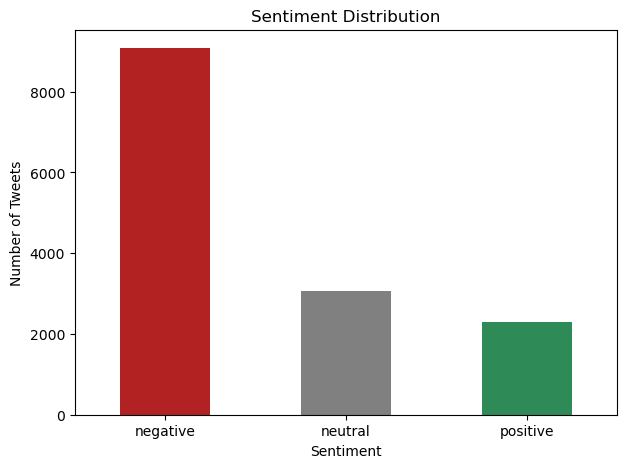

In [3]:
print(df['airline_sentiment'].value_counts())

df['airline_sentiment'].value_counts().plot(
    kind='bar', color=['firebrick', 'gray', 'seagreen'], figsize=(7,5))
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=0)
plt.show()

In [2]:
before = len(df)
df = df.drop_duplicates(subset='text').reset_index(drop=True)
print("Duplicates removed:", before - len(df))
print("Rows left:", len(df))

Duplicates removed: 213
Rows left: 14427


In [4]:
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Aarush\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Aarush\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Aarush\AppData\Roaming\nltk_data...


True

In [5]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# keep negation words: removing "not" would flip the meaning of a tweet
stop_words = set(stopwords.words('english')) - {'no', 'nor', 'not'}
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()                                # lowercase
    text = re.sub(r'http\S+|www\.\S+', ' ', text)      # remove URLs
    text = re.sub(r'@\w+', ' ', text)                  # remove @mentions
    text = re.sub(r'&amp;|&lt;|&gt;', ' ', text)       # remove HTML leftovers
    text = text.replace('#', ' ')                      # keep hashtag word, drop '#'
    text = text.replace("'", '').replace("’", '')      # didn't -> didnt
    text = re.sub(r'[^a-z\s]', ' ', text)              # remove punctuation, digits, emojis
    tokens = text.split()                              # tokenisation
    tokens = [w for w in tokens if w not in stop_words and len(w) > 1]   # stopword removal
    tokens = [lemmatizer.lemmatize(w) for w in tokens]                    # lemmatisation
    return ' '.join(tokens)

df['clean_text'] = df['text'].apply(clean_text)
df[['text', 'clean_text']].head(8)

,text,clean_text
0,@VirginAmerica What @dhepburn said.,said
1,@VirginAmerica plus you've added commercials t...,plus youve added commercial experience tacky
2,@VirginAmerica I didn't today... Must mean I n...,didnt today must mean need take another trip
3,@VirginAmerica it's really aggressive to blast...,really aggressive blast obnoxious entertainmen...
4,@VirginAmerica and it's a really big bad thing...,really big bad thing
5,@VirginAmerica seriously would pay $30 a fligh...,seriously would pay flight seat didnt playing ...
6,"@VirginAmerica yes, nearly every time I fly VX...",yes nearly every time fly vx ear worm wont go ...
7,@VirginAmerica Really missed a prime opportuni...,really missed prime opportunity men without ha...


## Text Preprocessing

Tweets are noisy, so each one goes through a cleaning pipeline before modelling:
- Lowercasing, so "Great" and "great" count as the same word
- Removing URLs, @mentions, HTML leftovers and the # symbol (the airline handle carries no sentiment)
- Removing punctuation, numbers and emojis
- Tokenisation: splitting each tweet into individual words
- Stopword removal: dropping very common words like "the" and "is" that carry little meaning. I kept "no", "nor" and "not" because removing negations would flip the meaning of a tweet ("not good" would become "good").
- Lemmatisation: reducing words to their base form ("delayed" becomes "delay") so related words are counted together

In [6]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df['airline_sentiment'])

y_train = train_df['airline_sentiment']
y_test = test_df['airline_sentiment']
print(train_df.shape, test_df.shape)

(11541, 3) (2886, 3)


## Feature Extraction: TF-IDF

Machine learning models can't read text, so each tweet has to be turned into numbers. TF-IDF (Term Frequency - Inverse Document Frequency) does this by giving each word a score:
- Term Frequency: how often the word appears in that tweet
- Inverse Document Frequency: how rare the word is across all tweets. Words that appear everywhere (like "flight") get a low weight, while distinctive words (like "worst" or "thanks") get a high weight.

This way the model focuses on the words that actually help tell sentiments apart. I fit the vectoriser on the training set only and then applied it to the test set, so no information from the test data leaks into training. I used the top 5,000 words and also included two-word phrases (for example "not good").

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train = tfidf.fit_transform(train_df['clean_text'])
X_test = tfidf.transform(test_df['clean_text'])
X_train.shape

(11541, 5000)

In [8]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

nb = MultinomialNB()
nb.fit(X_train, y_train)
nb_pred = nb.predict(X_test)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

In [9]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

for name, pred in [('Naive Bayes', nb_pred), ('Logistic Regression', lr_pred)]:
    print(f"--- {name} ---")
    print("Accuracy:", accuracy_score(y_test, pred))
    print(classification_report(y_test, pred))

--- Naive Bayes ---
Accuracy: 0.7418572418572419
              precision    recall  f1-score   support

    negative       0.73      0.98      0.84      1816
     neutral       0.75      0.26      0.38       612
    positive       0.86      0.44      0.58       458

    accuracy                           0.74      2886
   macro avg       0.78      0.56      0.60      2886
weighted avg       0.75      0.74      0.70      2886

--- Logistic Regression ---
Accuracy: 0.7938322938322938
              precision    recall  f1-score   support

    negative       0.82      0.94      0.87      1816
     neutral       0.67      0.49      0.57       612
    positive       0.82      0.63      0.71       458

    accuracy                           0.79      2886
   macro avg       0.77      0.69      0.72      2886
weighted avg       0.79      0.79      0.78      2886



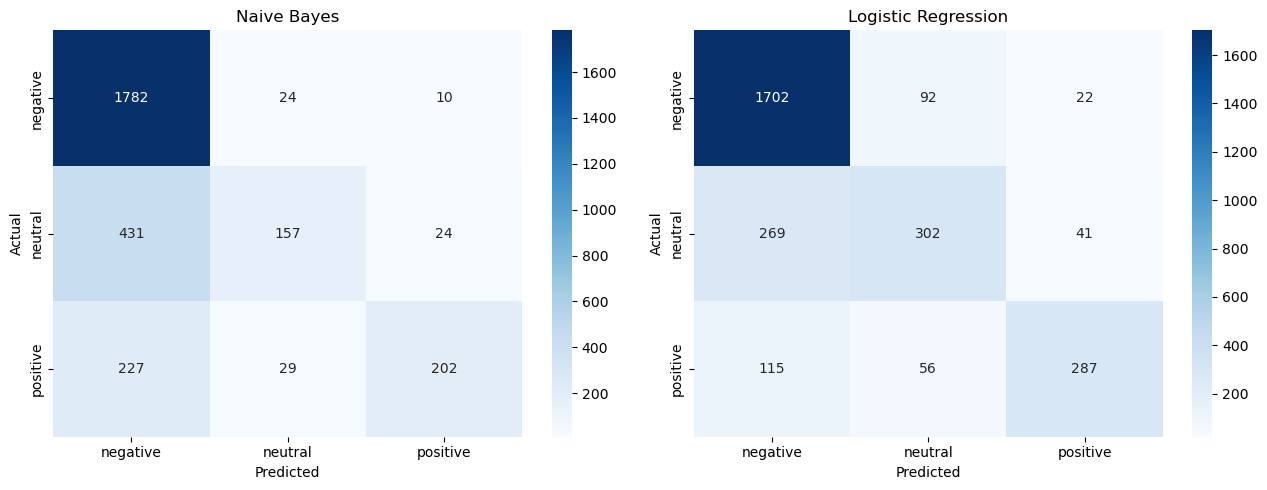

In [10]:
labels = ['negative', 'neutral', 'positive']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, pred) in zip(axes, [('Naive Bayes', nb_pred), ('Logistic Regression', lr_pred)]):
    cm = confusion_matrix(y_test, pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=labels, yticklabels=labels)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

In [11]:
comparison = pd.DataFrame({
    'Model': ['Naive Bayes', 'Logistic Regression'],
    'Accuracy': [accuracy_score(y_test, nb_pred), accuracy_score(y_test, lr_pred)]
})
comparison

,Model,Accuracy
0,Naive Bayes,0.741857
1,Logistic Regression,0.793832


In [12]:
!pip install wordcloud

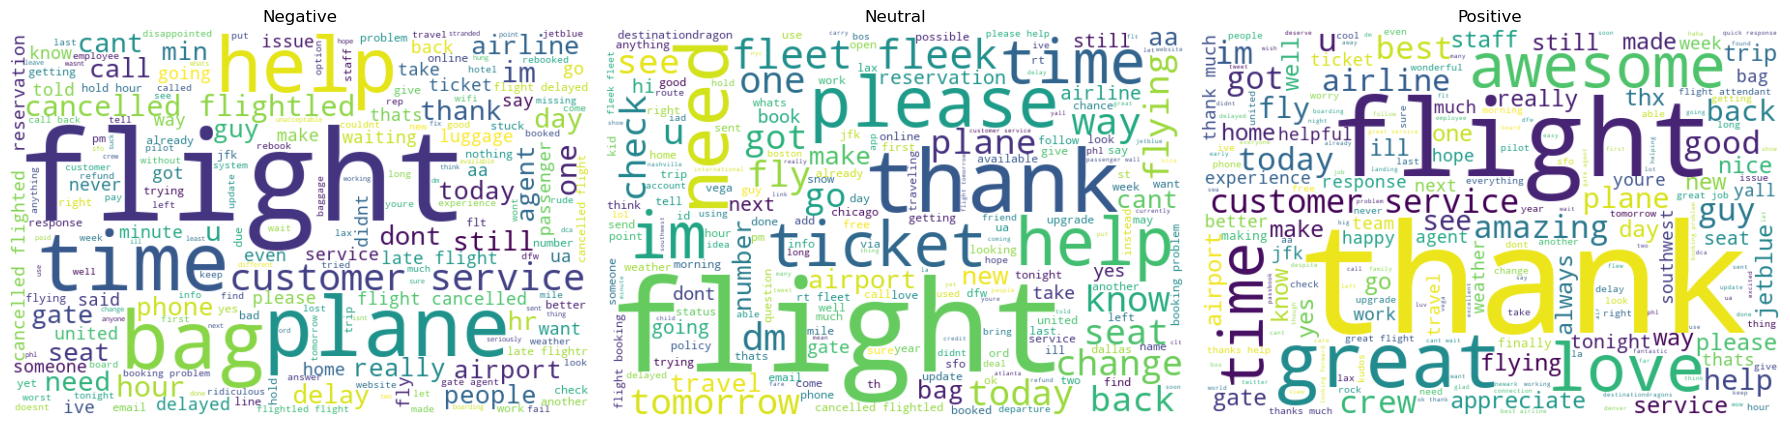

In [13]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, s in zip(axes, labels):
    text = ' '.join(df[df['airline_sentiment'] == s]['clean_text'])
    wc = WordCloud(width=600, height=400, background_color='white').generate(text)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(s.capitalize())
    ax.axis('off')
plt.tight_layout()
plt.show()

In [16]:
pd.set_option('display.max_colwidth', 200)

errors = test_df.copy()
errors['predicted'] = lr_pred
errors = errors[errors['predicted'] != errors['airline_sentiment']]

print("Total misclassified:", len(errors))
errors[['text', 'airline_sentiment', 'predicted']].head(5)

Total misclassified: 595


,text,airline_sentiment,predicted
3582,@united I forgot that Intl flights out of LAX don't go from Intl Terminal! Easiest re-check in ever! woo!,positive,negative
2061,@united all set. Figured it out at the baggage office!,neutral,negative
7351,"@JetBlue I have someone driving me, it's best to get a wheelchair once I get inside?",neutral,negative
4107,"@united 877 from amsterdam to ewr, 02.27.2015, 737-300.",neutral,negative
6252,@SouthwestAir @love_dragonss oh my god LAUREN OH MY GOD OH MY GOD,positive,negative


In [15]:
feature_names = np.array(tfidf.get_feature_names_out())
for i, c in enumerate(lr.classes_):
    print(c, '->', feature_names[np.argsort(lr.coef_[i])[-8:]])

negative -> ['bag' 'delayed' 'hr' 'hold' 'worst' 'no' 'not' 'hour']
neutral -> ['discount' 'ceo' 'question' 'avgeek' 'chance' 'possible' 'dm' 'hi']
positive -> ['thx' 'best' 'amazing' 'love' 'awesome' 'thank' 'great' 'thanks']
